# Optical Part - Sentinel-2 Imagery

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio

DATA = Path("./scenes")

S2_BANDS = ["B02", "B03", "B04"]
S2_BANDS.reverse()

S2_BAND_NAMES = {
    "B02": "Blue",
    "B03": "Green",
    "B04": "Red",
}

S2_BAND_COLORS = {
    "B04": "red",
    "B03": "green",
    "B02": "blue",
}

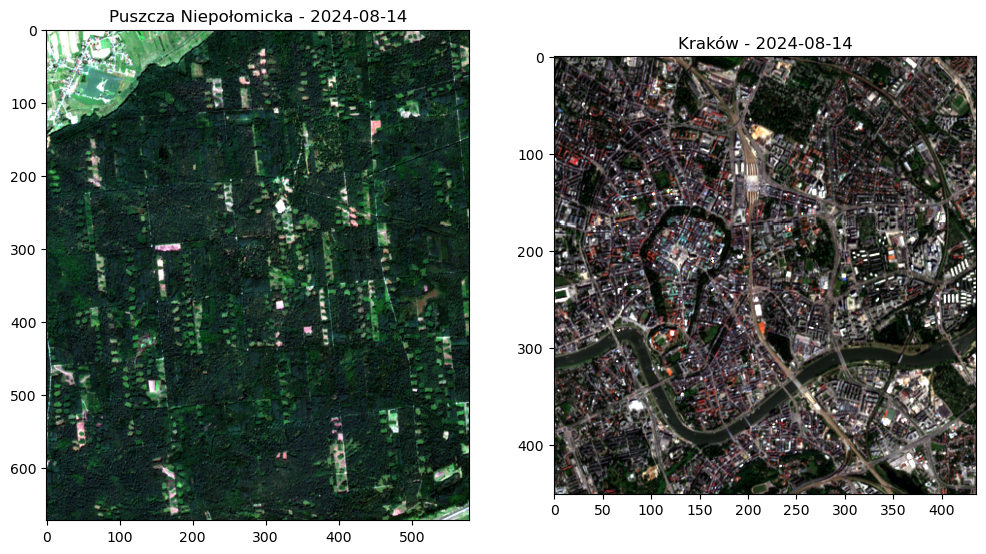

In [3]:
def percentile_stretch(array, lower_percentile=1, upper_percentile=99):
    p_low, p_high = np.percentile(array, (lower_percentile, upper_percentile))
    clipped = np.clip(array, p_low, p_high)
    return (clipped - p_low) / (p_high - p_low)

def get_raster_image(filename: str) -> np.ndarray:
    image_bands = []

    for band in S2_BANDS:
        with rasterio.open(DATA / f"{filename}_{band}.tif") as src:
            image_bands.append(src.read(1))

    return np.dstack([percentile_stretch(band) for band in image_bands])


def display_raster_image(first_image: np.ndarray, second_image: np.ndarray, first_title: str = "", second_title: str = ""):
    _, ax = plt.subplots(1, 2, figsize=(12, 12))
    ax[0].imshow(first_image)
    ax[1].imshow(second_image)
    ax[0].set_title(first_title)
    ax[1].set_title(second_title)
    plt.show()


s2_natural = get_raster_image("s2_natural")
s2_urban = get_raster_image("s2_urban")

display_raster_image(s2_natural, s2_urban, "Puszcza Niepołomicka - 2024-08-14", "Kraków - 2024-08-14")


Puszcza Niepołomicka average color: #213A2D
Kraków average color: #43403C


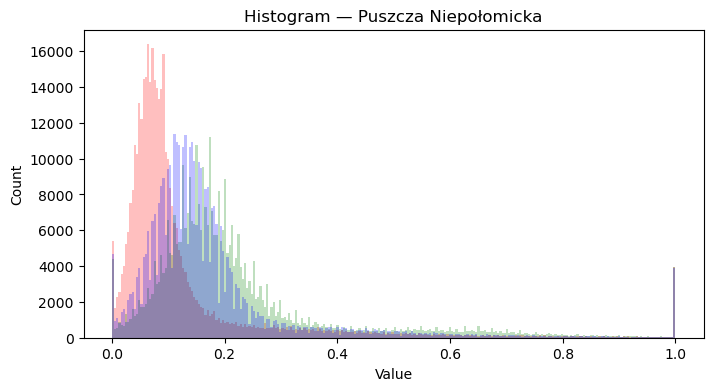

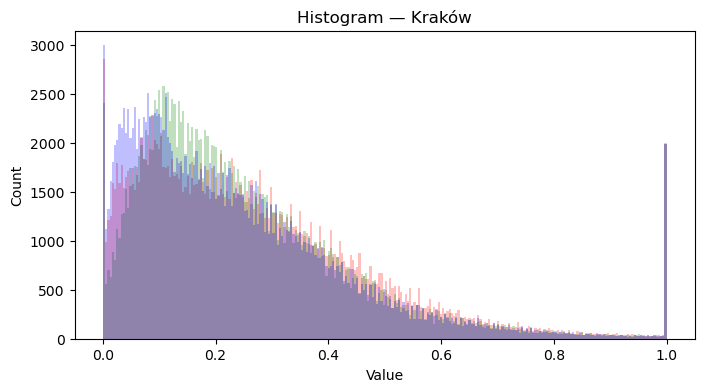

In [4]:
def histogram(image: np.ndarray, scene_name: str):
    plt.figure(figsize=(8, 4))
    for ix, band in enumerate(S2_BANDS):
        plt.hist(
            image[:, :, ix].ravel(),
            bins=256,
            range=(0, 1),
            alpha=0.25,
            label=S2_BAND_NAMES[band],
            color=S2_BAND_COLORS[band],
        )
    plt.title(f"Histogram — {scene_name}")
    plt.xlabel("Value")
    plt.ylabel("Count")
    plt.show()


# Little experiment
def average_color(image: np.ndarray) -> np.ndarray:
    h, w, c = image.shape
    means = image.sum(axis=(0, 1)) / (h * w)
    return means

print("Puszcza Niepołomicka average color:", "#" + "".join(f"{int(avg * 255):02X}" for avg in average_color(s2_natural)))
print("Kraków average color:", "#" + "".join(f"{int(avg * 255):02X}" for avg in average_color(s2_urban)))

histogram(s2_natural, "Puszcza Niepołomicka")
histogram(s2_urban, "Kraków")


## SENTINEL-2 Observations

What is the most interesting for me in Sentinel-2 imagery is the fact that even before computing the average color is the fact that urban scene histogram tells us straight away that the image is "grayish", that it represents urban development, whole lot of buildings, roads etc. Each component of the pixel (each color) tend to have similar values with little varying. Forest scene on the other hand points to the dominance of greenish colors and more sophisticated colors, much more happens here (wider spread, red peaking at lower values, green is more stretched on x-axis). So even if we would have not seen the rasters we generally could have told what those images represent.

## Steganography

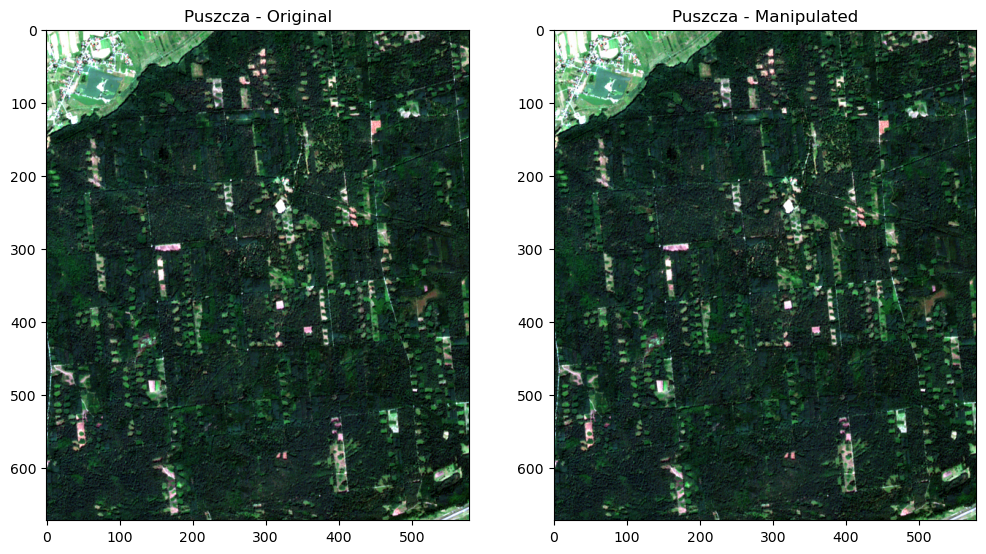

In [20]:
def replace_two_lsbs(image_float: np.ndarray, seed: int = 42) -> np.ndarray:
    rng = np.random.default_rng(seed)

    img8 = (np.clip(image_float, 0, 1) * 255).astype(np.uint8)

    cleared = img8 & 0b11111100
    noise = rng.integers(0, 4, size=img8.shape, dtype=np.uint8)
    manipulated = cleared | noise

    return manipulated.astype(np.float32) / 255.0


original = s2_natural
manipulated = replace_two_lsbs(original)

display_raster_image(original, manipulated, "Puszcza - Original", "Puszcza - Manipulated")

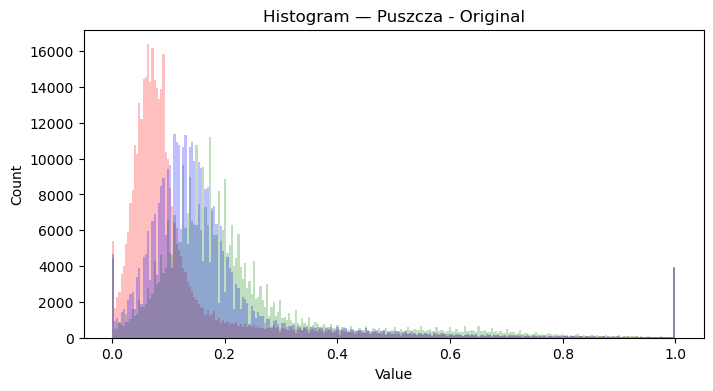

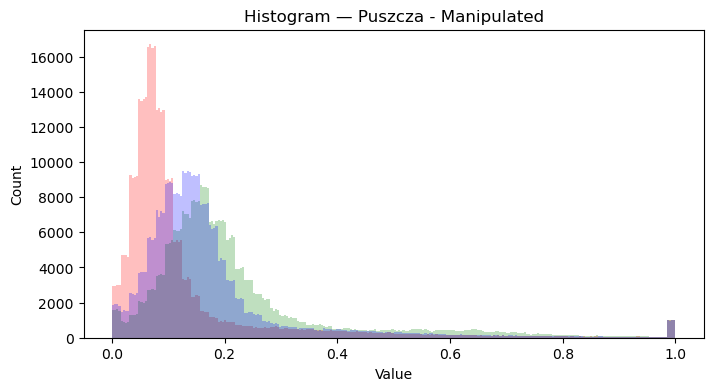

In [21]:
histogram(original, "Puszcza - Original")
histogram(manipulated, "Puszcza - Manipulated")

## Answer
No visual change is visible on the image so far, but the histogram differ dramatically. Number of individual bins is removed. More parts of the histogram appear flat. Histogram is more uniform/ I don't think this is a robust detector of manipulations. However it can point towards something, not processed scene propably does not look like that, it is highly unlikely. But it does not necessary mean that imagery was tampered with, it could be processing, compression or something else also.